Ticket: https://open-jira.nrao.edu/browse/PIPE-2936

Compare ALMA locations from different sources.

First thing to note: the location I hardcoded into PIPE-2936 originally (`_ALMA_GEOCENTRIC = (2225122.3902694373, -5440258.9852695046, -2481007.6374628348)  # CASA WGS84 coords`) is certainly wrong (they can be found here among other places: https://safe.nrao.edu/wiki/bin/view/ALMA/Long2xyz). It's not the location of the telescope, but of the observatory building! See the pin at the top of this Google Maps image:

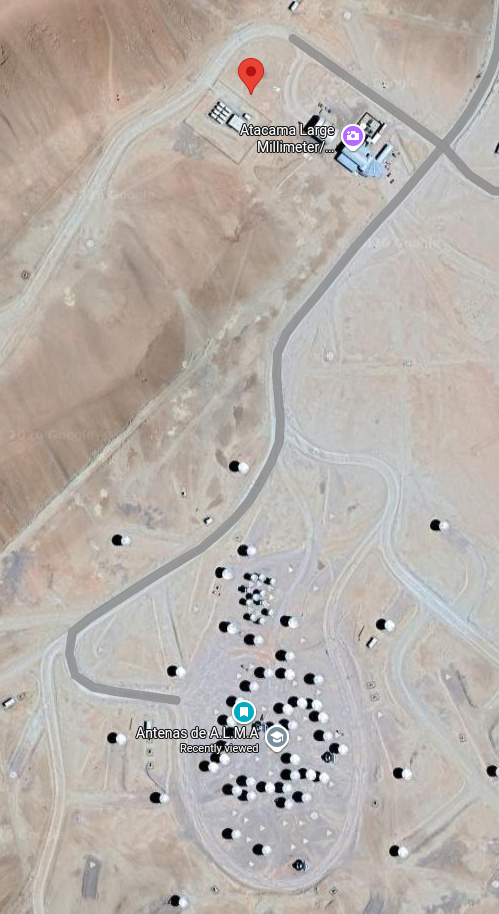

The blue-white bookmark icon at the bottom is the location that astropy gives. Also doesn't seem perfect. These are exactly the coordinates that are published here: https://almascience.nrao.edu/about-alma/alma-site; "latitude: -23.029° ; longitude: -67.755°" and "altitude of 5000 meters". All not very precise.

In [1]:
from pipeline.infrastructure import casa_tools

2026-06-05 08:48:45 INFO: Pipeline version 2026.1.1.45+7-g2db91ce3e-PIPE-2936 running on eddington.desktop.astro.rug.nl
2026-06-05 08:48:45 INFO: Host environment:
	CPU: Intel(R) Core(TM) i7-14700T (physical cores: 20, logical cores: 28)
	Memory: 30.7 GiB RAM, unknown swap
	OS: Rocky Linux 9.7 (Blue Onyx)
	cgroup limits: N/A of 28 CPU cores, memory limits=N/A
	ulimit limits: CPU time=N/A, memory=N/A, files=4096
2026-06-05 08:48:45 INFO: Environment as detected by CASA:
	CPUs reported by CASA: 28 cores, max 28 OpenMP threads
	Available memory: 30.7 GiB


In [2]:
from unittest.mock import Mock

In [3]:
from pipeline.domain.measurementset import MeasurementSet

In [4]:
ms = Mock(spec=MeasurementSet)
ms.antenna_array = Mock()
ms.antenna_array.name = 'ALMA'

In [5]:
me = casa_tools.measures

In [6]:
me.observatory(ms.antenna_array.name)

{'m0': {'unit': 'rad', 'value': -1.1825465955049892},
 'm1': {'unit': 'rad', 'value': -0.4018251640113072},
 'm2': {'unit': 'm', 'value': 5056.8},
 'refer': 'WGS84',
 'type': 'position'}

In [8]:
casa_location = me.observatory(ms.antenna_array.name)

In [15]:
# my hardcoded location
_ALMA_GEOCENTRIC = (2225122.3902694373, -5440258.9852695046, -2481007.6374628348)  # CASA WGS84 coords

In [12]:
from astropy.coordinates import EarthLocation
import numpy as np

In [42]:
# casa_location
casa_location_geo = EarthLocation.from_geodetic(casa_location['m0']['value']/np.pi*180, casa_location['m1']['value']/np.pi*180, casa_location['m2']['value'])
casa_location_geo

<EarthLocation (2225142.18026897, -5440307.37034856, -2481029.85187355) m>

In [43]:
casa_location_geo.to_geodetic()

GeodeticLocation(lon=<Longitude -67.754929 deg>, lat=<Latitude -23.022886 deg>, height=<Quantity 5056.8 m>)

In [44]:
# casa location, but with the height hardcoded to exactly 5000m
casa_location_5k_geo = EarthLocation.from_geodetic(casa_location['m0']['value']/np.pi*180, casa_location['m1']['value']/np.pi*180, 5000)
casa_location_5k_geo

<EarthLocation (2225122.39026944, -5440258.9852695, -2481007.63746283) m>

In [45]:
casa_location_5k_geo.to_geodetic()

GeodeticLocation(lon=<Longitude -67.754929 deg>, lat=<Latitude -23.022886 deg>, height=<Quantity 5000. m>)

In [46]:
# my previously hardcoded location
hardcoded_location_geo = EarthLocation.from_geocentric(*_ALMA_GEOCENTRIC, unit="m")
hardcoded_location_geo

<EarthLocation (2225122.39026944, -5440258.9852695, -2481007.63746283) m>

In [47]:
hardcoded_location_geo.to_geodetic()

GeodeticLocation(lon=<Longitude -67.754929 deg>, lat=<Latitude -23.022886 deg>, height=<Quantity 5000. m>)

In [48]:
# they are the same:
casa_location_5k_geo == hardcoded_location_geo

np.True_

So I used the CASA lat/lon but with 5000m height; not completely sure why I chose to use 5000m instead of the CASA given value.

Unfortunately, all of these locations seem to be quite wrong (see image above). The astropy location is much better, but as mentioned above is simply the imprecise coordinates copied from the ALMA public website:

In [30]:
astropy_location = EarthLocation.of_site(ms.antenna_array.name)
astropy_location

<EarthLocation (2225015.30883296, -5440016.41799762, -2481631.27428014) m>

In [34]:
astropy_location.to_geodetic()

GeodeticLocation(lon=<Longitude -67.755 deg>, lat=<Latitude -23.029 deg>, height=<Quantity 5000. m>)

In [32]:
astropy_location.ellipsoid

'WGS84'

In [36]:
casa_location_5k_astropy.ellipsoid

'WGS84'

To further complicate things, there is actually yet another hardcoded value in the pipeline! https://open-bitbucket.nrao.edu/projects/PIPE/repos/pipeline/browse/pipeline/hifa/tasks/flagging/flagdeteralma.py#794 Let's see how that one compares:

In [50]:
alma_site = EarthLocation.from_geocentric(x=2225015.30883296, y=-5440016.41799762, z=-2481631.27428014, unit='m')

In [51]:
alma_site.to_geodetic()

GeodeticLocation(lon=<Longitude -67.755 deg>, lat=<Latitude -23.029 deg>, height=<Quantity 5000. m>)

So actually they hardcoded the astropy location here!

In [64]:
alma_site.itrs.cartesian - astropy_location.itrs.cartesian

<CartesianRepresentation (x, y, z) in m
    (1.86264515e-09, -2.79396772e-09, -4.19095159e-09)>

Well, almost